In [207]:
import numpy as np
rng = np.random.default_rng()

import seaborn as sns

In [208]:
risk_probabilities = np.array([1.0,0.0,0.0])  # the probability of being no risk, risky, risky + recent infection
#risk_probabilities = np.array([0.6,0.3,0.1])
risk_ratios = np.array([1,1.5,2])
true_strain_probs = rng.dirichlet([60,30,10])  # first line susceptible, second line susceptible, total resistance
uti_prev = rng.beta(1,9)  # total uti prevalence

# generate patients
num_patients = 1000
patients = []
uti_count = 0
strain_counts = np.array([0,0,0])

for i in range(0,num_patients):
    risk_fac = risk_ratios[rng.choice(3, p=risk_probabilities)]
    uti_prob = min(risk_fac*uti_prev, 1)
    uti_status=(rng.binomial(1,uti_prob)==1)
    patient_status = {"uti_status": uti_status, "uti_strain": None, "risk_factor": risk_fac}
    if uti_status:
        patient_status["uti_strain"] = rng.choice(3, p=true_strain_probs)
        uti_count += 1
        strain_counts[patient_status["uti_strain"]] += 1

    patients.append(patient_status)

print(f"True UTI prevalence: {uti_prev}")
print(f"Measured UTI prevalence: {uti_count/num_patients}\n")

print(f"True strain breakdown: {true_strain_probs}")
print(f"Strain breakdown: {strain_counts/uti_count}")

True UTI prevalence: 0.048395445142128436
Measured UTI prevalence: 0.045

True strain breakdown: [0.54212184 0.3082032  0.14967496]
Strain breakdown: [0.51111111 0.35555556 0.13333333]


In [209]:
# define the capabilities of the diagnostics
phys_uti_prev = 0.15
phys_strain_probs = [0.5,0.35,0.15]
diag_sens_spec = {"dipstick": [0.7,0.05], "urine_culture": [0.9,0.03], "rapid_test": [0.95,0.01], "rapid_plus_ast": [0.95,0.0]}

# valid choices are clinical, dipstick, urine_culture, rapid_test, rapid_plus_ast
def diagnostic_output(patient_status, strategy="clinical"):
    # by default, there is no strain chosen
    strain_diagnosis = None

    # evaluate patient using chosen strategy
    if strategy == "clinical":
        uti_diagnosis = (1==rng.binomial(1, patient_status["risk_factor"]*phys_uti_prev))
        if uti_diagnosis:
            strain_diagnosis = rng.choice(3, p=phys_strain_probs)
    
    elif strategy in ["dipstick", "urine_culture", "rapid_test"]:
        if patient_status["uti_status"]:
            true_pos_prob = diag_sens_spec[strategy][0]
            uti_diagnosis = (1==rng.binomial(1, true_pos_prob))
        else:
            false_pos_prob = diag_sens_spec[strategy][1]
            uti_diagnosis = (1==rng.binomial(1, false_pos_prob))
        
        if uti_diagnosis:
            strain_diagnosis = rng.choice(3, p=phys_strain_probs)
    
    elif strategy == "rapid_plus_ast":
        if patient_status["uti_status"]:
            true_pos_prob = diag_sens_spec["rapid_plus_ast"][0]
            uti_diagnosis = (1==rng.binomial(1, true_pos_prob))
        else:
            false_pos_prob = diag_sens_spec["rapid_plus_ast"][1]
            uti_diagnosis = (1==rng.binomial(1, false_pos_prob))
        
        if uti_diagnosis:
            strain_diagnosis = patient_status["uti_strain"]  # what happens if this is a false positive??
    
    else:
        raise ValueError(f"Invalid diagnostic strategy: {strategy}")
    
    return uti_diagnosis, strain_diagnosis

In [210]:
chosen_strategy = "rapid_plus_ast"
# to analyze the success rates of the strategies, we compute confusion matrices for both strain diagnosis
# and whether the uti was detected in the first place 
strain_confusion_matrix = np.zeros((len(true_strain_probs),len(true_strain_probs)))
uti_confusion_matrix = np.zeros((2,2))
overall_confusion_matrix = np.zeros((1+len(true_strain_probs),1+len(true_strain_probs)))

for patient_status in patients:
    true_uti_status, true_strain = patient_status["uti_status"], patient_status["uti_strain"]
    phys_uti_diag, phys_uti_strain = diagnostic_output(patient_status, strategy=chosen_strategy)

    if phys_uti_diag:
        total_phys_index = phys_uti_strain + 1
    else:
        total_phys_index = 0
    
    if true_uti_status:
        total_true_index = true_strain + 1
    else:
        total_true_index = 0
    overall_confusion_matrix[total_true_index, total_phys_index] += 1 

    # if physician has correctly determined there is a uti, check if they get the strain right
    if true_uti_status and phys_uti_diag:
        strain_confusion_matrix[true_strain, phys_uti_strain] += 1 

    true_uti_status = int(true_uti_status)
    phys_uti_status = int(phys_uti_diag)
    uti_confusion_matrix[true_uti_status, phys_uti_status] +=1


<Axes: >

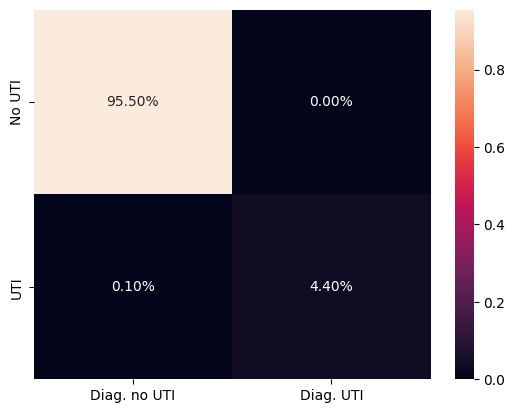

In [211]:
uti_confusion_matrix /= np.sum(uti_confusion_matrix)
sns.heatmap(uti_confusion_matrix, yticklabels=["No UTI", "UTI"], xticklabels=["Diag. no UTI", "Diag. UTI"], annot=True, fmt=".2%")

<Axes: >

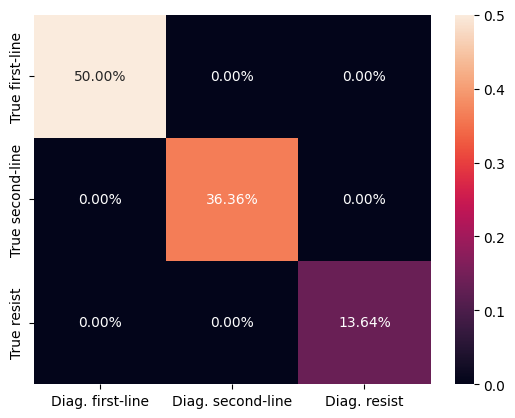

In [212]:
strain_confusion_matrix /= np.sum(strain_confusion_matrix)
sns.heatmap(strain_confusion_matrix, yticklabels=["True first-line", "True second-line", "True resist"], 
xticklabels=["Diag. first-line", "Diag. second-line", "Diag. resist"],annot=True,fmt=".2%")

<Axes: >

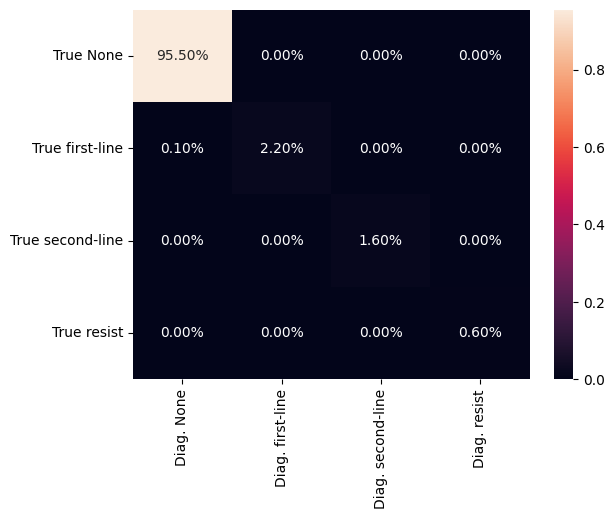

In [213]:
overall_confusion_matrix /= np.sum(overall_confusion_matrix)
sns.heatmap(overall_confusion_matrix, yticklabels=["True None", "True first-line", "True second-line", "True resist"], 
xticklabels=["Diag. None", "Diag. first-line", "Diag. second-line", "Diag. resist"],annot=True,fmt=".2%")